# **Import Libraries**

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# it helps to load the dataset
from datasets import load_dataset

# **Load Dataset**

In [ ]:
emotion_dataset = load_dataset('dair-ai/emotion')
train_text = emotion_dataset['train']['text']
train_label = emotion_dataset['train']['label']

val_text = emotion_dataset['validation']['text']
val_label = emotion_dataset['validation']['label']

test_text = emotion_dataset['test']['text']
test_label = emotion_dataset['test']['label']

In [ ]:
label_names = emotion_dataset['train'].features['label'].names

In [ ]:
df_train = pd.DataFrame({
    'text': train_text,
    'label' : [label_names[i] for i in train_label]
})


df_test = pd.DataFrame({
    'text': test_text,
    'label' : [label_names[i] for i in test_label]
})

df_validation = pd.DataFrame({
    'text': val_text,
    'label': [label_names[i] for i in val_label]
})

In [ ]:
df_train.head()

,text,label
0,i didnt feel humiliated,sadness
1,i can go from feeling so hopeless to so damned...,sadness
2,im grabbing a minute to post i feel greedy wrong,anger
3,i am ever feeling nostalgic about the fireplac...,love
4,i am feeling grouchy,anger


In [ ]:
df_test.head()

,text,label
0,im feeling rather rotten so im not very ambiti...,sadness
1,im updating my blog because i feel shitty,sadness
2,i never make her separate from me because i do...,sadness
3,i left with my bouquet of red and yellow tulip...,joy
4,i was feeling a little vain when i did this one,sadness


In [ ]:
df_validation.head()

,text,label
0,im feeling quite sad and sorry for myself but ...,sadness
1,i feel like i am still looking at a blank canv...,sadness
2,i feel like a faithful servant,love
3,i am just feeling cranky and blue,anger
4,i can have for a treat or if i am feeling festive,joy


In [ ]:
print(df_train.shape)
print(df_test.shape)
print(df_validation.shape)

(16000, 2)
(2000, 2)
(2000, 2)


In [ ]:
print(df_train.isnull().sum())
print()
print()
print(df_test.isnull().sum())
print()
print()
print(df_validation.isnull().sum())

text     0
label    0
dtype: int64


text     0
label    0
dtype: int64


text     0
label    0
dtype: int64


# ***Exploratory Data Analysis (EDA)***

In [ ]:
df_train['label'].value_counts()

,count
label,
joy,5362
sadness,4666
anger,2159
fear,1937
love,1304
surprise,572


In [ ]:
df_train['label'].value_counts().index

Index(['joy', 'sadness', 'anger', 'fear', 'love', 'surprise'], dtype='object', name='label')

<Axes: xlabel='label', ylabel='count'>

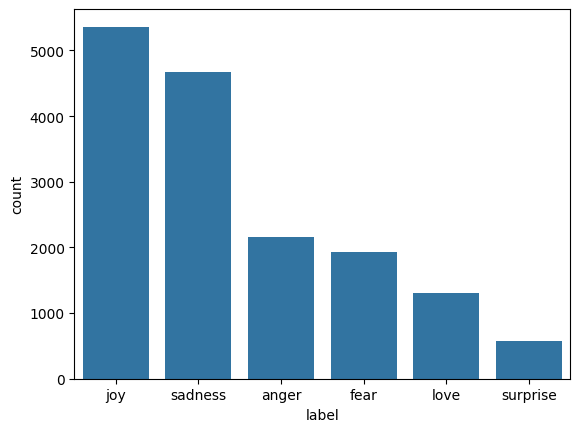

In [ ]:
sns.countplot(x='label',data=df_train,order=df_train['label'].value_counts().index)


<Axes: xlabel='label', ylabel='count'>

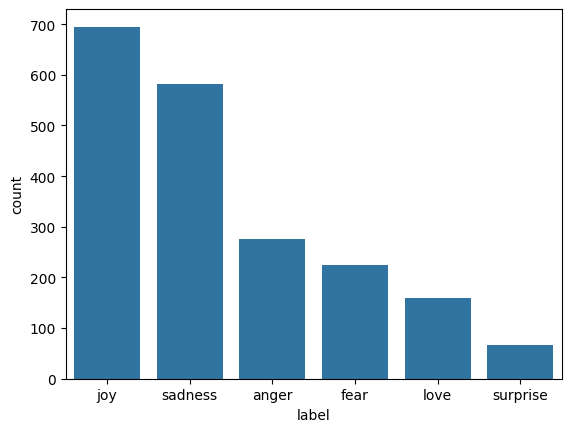

In [ ]:
sns.countplot(x='label',data=df_test,order=df_test['label'].value_counts().index)

# ***Data Preprocessing - Using NLP***

**Tokenize text,pad sequences to max length 50,and convert labels to NumPy arrays**

In [ ]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

max_words = 15000

tokenizer = Tokenizer(num_words=max_words,oov_token='<unk>')
tokenizer.fit_on_texts(df_train['text'])

train_sequence = tokenizer.texts_to_sequences(df_train['text'])
test_sequence = tokenizer.texts_to_sequences(df_test['text'])
val_sequence = tokenizer.texts_to_sequences(df_validation['text'])

padded_train_sequence = pad_sequences(train_sequence,maxlen=50,padding='post',truncating='post')
padded_test_sequence = pad_sequences(test_sequence,maxlen=50,padding='post',truncating='post')
padded_val_sequence = pad_sequences(val_sequence,maxlen=50,padding='post',truncating='post')

train_labels = np.array(train_label)
test_labels = np.array(test_label)
val_labels = np.array(val_label)

num_classes = len(np.unique(train_labels))


print(f'Vocabulary Size: {len(tokenizer.word_index)}')
print(f'Max Sentence Lenght:{padded_train_sequence.shape[1]}')

Vocabulary Size: 15213
Max Sentence Lenght:50


In [ ]:
lengths = [len(x.split()) for x in train_text]

print(np.percentile(lengths,50))
print(np.percentile(lengths,90))
print(np.percentile(lengths,95))
print(np.percentile(lengths,99))

17.0
35.0
41.0
52.0


In [ ]:
df_train['label'].value_counts()

,count
label,
joy,5362
sadness,4666
anger,2159
fear,1937
love,1304
surprise,572


# **Shared Training Utilities**

fixing class imbalanced dataset

In [ ]:
from sklearn.utils import class_weight

class_weights = class_weight.compute_class_weight(
    class_weight = 'balanced',
    classes = np.unique(train_labels),
    y = train_labels
)

class_weight_dict = dict(enumerate(class_weights))

# **Applying early stopping**

In [ ]:
from tensorflow.keras.callbacks import EarlyStopping

early_stopping = EarlyStopping(
    monitor = 'val_loss',
    patience=3,
    restore_best_weights=True
)

# **Phase 1 - Plain Foundational Modals**

Train plain(non-bidirectional) Simple RNN, Standard LSTM and Standard GRU models

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN,Embedding,Dense,Dropout,LSTM,GRU

# Model 1 - Simple RNNs

In [ ]:
# rnn_model = Sequential([
#     Embedding(input_dim=max_words,output_dim=128,input_length=50),
#     SimpleRNN(units=128,return_sequences=True),
#     Dropout(0.5),
#     SimpleRNN(units=64),
#     Dropout(0.5),
#     Dense(units=num_classes,activation='softmax')
# ])


# rnn_model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])


# # Train the model
# rnn_model.fit(
#     padded_train_sequence,
#     train_labels,
#     validation_data=(padded_test_sequence,test_labels),
#     epochs = 40,
#     batch_size = 32,
#     class_weight=class_weight_dict,
#     callbacks=[early_stopping]
#     )


# rnn_loss,rnn_accuracy = rnn_model.evaluate(padded_test_sequence,test_labels)
# print(f"RNN Loss: {rnn_loss}")
# print(f"RNN Accuracy: {rnn_accuracy}")

In [ ]:
# rnn_model = Sequential([
#     Embedding(input_dim=max_words,output_dim=128,input_length=50),
#     SimpleRNN(units=256,return_sequences=True),
#     Dropout(0.5),
#     SimpleRNN(units=128,return_sequences=True),
#     Dropout(0.5),
#     SimpleRNN(units=64),
#     Dropout(0.5),
#     Dense(units=32,activation='relu'),
#     Dense(units=num_classes,activation='softmax')
# ])


# rnn_model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])


# # Train the model
# rnn_model.fit(
#     padded_train_sequence,
#     train_labels,
#     validation_data=(padded_test_sequence,test_labels),
#     epochs = 40,
#     batch_size = 32,
#     class_weight=class_weight_dict,
#     callbacks=[early_stopping]
#     )


# rnn_loss,rnn_accuracy = rnn_model.evaluate(padded_test_sequence,test_labels)
# print(f"RNN Loss: {rnn_loss}")
# print(f"RNN Accuracy: {rnn_accuracy}")

# Model 2 - Standard LSTM

In [ ]:
# lstm_model = Sequential([
#     Embedding(input_dim=max_words, output_dim=128, input_length=50),
#     Bidirectional(LSTM(units=128,return_sequences=True)),
#     Dropout(0.5),
#     Bidirectional(LSTM(units=64)),
#     Dropout(0.5),
#     Dense(units=num_classes,activation='softmax')
# ])


# lstm_model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])


# #train model
# lstm_model.fit(
#     padded_train_sequence,
#     train_labels,
#     validation_data = (padded_test_sequence,test_labels),
#     epochs=20,
#     batch_size = 32,
#     class_weight = class_weight_dict,
#     callbacks = [early_stopping]
# )


# lstm_loss,lstm_accuracy = lstm_model.evaluate(padded_test_sequence,test_labels)
# print(f"LSTM Loss: {lstm_loss}")
# print(f"LSTM Accuracy: {lstm_accuracy}")




In [ ]:
# lstm_model = Sequential([
#     Embedding(input_dim=max_words,output_dim=128,input_length=50),
#     LSTM(units=256,return_sequences=True),
#     Dropout(0.5),
#     LSTM(units=128,return_sequences=True),
#     Dropout(0.5),
#     LSTM(units=64),
#     Dropout(0.5),
#     Dense(units=num_classes,activation='softmax')
# ])


# lstm_model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])


# lstm_model.fit(
#     padded_train_sequence,
#     train_labels,
#     validation_data = (padded_test_sequence,test_labels),
#     epochs=20,
#     batch_size = 32,
#     class_weight = class_weight_dict,
#     callbacks = [early_stopping]
# )


# lstm_loss,lstm_accuracy = lstm_model.evaluate(padded_test_sequence,test_labels)
# print(f"LSTM Loss: {lstm_loss}")
# print(f"LSTM Accuracy: {lstm_accuracy}")

# Model-3 Standard GRU

In [ ]:
# gru_model = Sequential([
#     Embedding(input_dim=max_words, output_dim=128, input_length=50),
#     GRU(units=128,return_sequences=True),
#     Dropout(0.5),
#     GRU(units=64),
#     Dropout(0.5),
#     Dense(units=num_classes,activation='softmax')
# ])


# gru_model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])


# #train model
# gru_model.fit(
#     padded_train_sequence,
#     train_labels,
#     validation_data = (padded_test_sequence,test_labels),
#     epochs=20,
#     batch_size = 32,
#     class_weight = class_weight_dict,
#     callbacks = [early_stopping]
# )


# gru_loss,gru_accuracy = gru_model.evaluate(padded_test_sequence,test_labels)
# print(f"GRU Loss: {gru_loss}")
# print(f"GRU Accuracy: {gru_accuracy}")




In [ ]:
# gru_model = Sequential([
#     Embedding(input_dim=max_words, output_dim=128, input_length=50),
#     GRU(units=256,return_sequences=True),
#     Dropout(0.5),
#     GRU(units=128,return_sequences=True),
#     Dropout(0.5),
#     GRU(units=64),
#     Dropout(0.5),
#     Dense(units=num_classes,activation='softmax')
# ])


# gru_model.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])


# #train model
# gru_model.fit(
#     padded_train_sequence,
#     train_labels,
#     validation_data = (padded_test_sequence,test_labels),
#     epochs=20,
#     batch_size = 32,
#     class_weight = class_weight_dict,
#     callbacks = [early_stopping]
# )


# gru_loss,gru_accuracy = gru_model.evaluate(padded_test_sequence,test_labels)
# print(f"GRU Loss: {gru_loss}")
# print(f"GRU Accuracy: {gru_accuracy}")




# Phase 1 Ranking & Selection

In [ ]:
# result_df = pd.DataFrame({
#     'Model': ['RNN','LSTM','GRU'],
#     'Test Loss' : [rnn_loss,lstm_loss,gru_loss],
#     'Test Accuracy' : [rnn_accuracy,lstm_accuracy,gru_accuracy]
# }).sort_values(by='Test Accuracy',ascending=False)

# result_df

In [ ]:
from tensorflow.keras.layers import SpatialDropout1D
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import ReduceLROnPlateau

In [ ]:
reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.5,
    patience=2,
    verbose=1,
    min_lr=1e-6
)

In [ ]:
from tensorflow.keras.regularizers import l2



# ***Phase 2 - Advanced Bidirectional GRU***

# Model 4 -- Advanced Stacked Bidirectional GRU

In [ ]:
# from tensorflow.keras.layers import Bidirectional

# BiGRU = Sequential([
#     Embedding(input_dim=max_words,output_dim=200,input_shape = (50,)),
#     SpatialDropout1D(0.3),
#     Bidirectional(GRU(128,return_sequences=True,dropout=0.3,kernel_regularizer=l2(1e-4))),
#     Dropout(0.3),
#     Bidirectional(GRU(64,dropout=0.3,kernel_regularizer=l2(1e-4))),
#     Dense(64,activation='relu',kernel_regularizer=l2(1e-4)),
#     Dropout(0.4),
#     Dense(num_classes,activation='softmax')
# ])


# BiGRU.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['accuracy'])

# BiGRU.summary()





In [ ]:
# from tensorflow.keras.models import Sequential
# from tensorflow.keras.layers import (
#     Embedding,
#     Bidirectional,
#     GRU,
#     Dense,
#     Dropout,
#     SpatialDropout1D
# )
# from tensorflow.keras.regularizers import l2

# BiGRU = Sequential([

#     Embedding(
#         input_dim=max_words,
#         output_dim=300,
#         input_length=50
#     ),

#     SpatialDropout1D(0.3),

#     Bidirectional(
#         GRU(
#             256,
#             return_sequences=True,
#             dropout=0.3,
#             recurrent_dropout=0.2,
#             kernel_regularizer=l2(1e-4)
#         )
#     ),

#     Bidirectional(
#         GRU(
#             128,
#             dropout=0.3,
#             recurrent_dropout=0.2,
#             kernel_regularizer=l2(1e-4)
#         )
#     ),

#     Dense(
#         128,
#         activation='relu',
#         kernel_regularizer=l2(1e-4)
#     ),

#     Dropout(0.5),

#     Dense(
#         64,
#         activation='relu'
#     ),

#     Dropout(0.3),

#     Dense(
#         num_classes,
#         activation='softmax'
#     )
# ])

# BiGRU.compile(
#     optimizer='adam',
#     loss='sparse_categorical_crossentropy',
#     metrics=['accuracy']
# )

# BiGRU.summary()

Train & Evaluate Advanced Bidirectional GRU

In [ ]:
# from tensorflow.keras.models import Model
# from tensorflow.keras.layers import (
#     Input,
#     Embedding,
#     Bidirectional,
#     GRU,
#     Dense,
#     Dropout,
#     SpatialDropout1D,
#     Layer
# )
# import tensorflow as tf

# class AttentionLayer(Layer):
#     def build(self, input_shape):
#         self.W = self.add_weight(
#             shape=(input_shape[-1],1),
#             initializer='glorot_uniform',
#             trainable=True
#         )

#     def call(self,x):
#         scores = tf.nn.tanh(tf.matmul(x,self.W))
#         weights = tf.nn.softmax(scores,axis=1)
#         context = tf.reduce_sum(weights*x,axis=1)
#         return context

# inputs = Input(shape=(50,))

# x = Embedding(
#     input_dim=max_words,
#     output_dim=300,
#     input_length=50
# )(inputs)

# x = SpatialDropout1D(0.3)(x)

# x = Bidirectional(
#     GRU(
#         128,
#         return_sequences=True,
#         dropout=0.3,
#         recurrent_dropout=0.2
#     )
# )(x)

# x = Bidirectional(
#     GRU(
#         64,
#         return_sequences=True,
#         dropout=0.3,
#         recurrent_dropout=0.2
#     )
# )(x)

# x = AttentionLayer()(x)

# x = Dense(128,activation='relu')(x)
# x = Dropout(0.5)(x)

# outputs = Dense(
#     num_classes,
#     activation='softmax'
# )(x)

# model = Model(inputs,outputs)

# model.compile(
#     optimizer='adam',
#     loss='sparse_categorical_crossentropy',
#     metrics=['accuracy']
# )

# model.summary()

In [ ]:
# # Train the model
# model.fit(
#     padded_train_sequence,
#     train_labels,
#     validation_data=(padded_val_sequence, val_labels),
#     epochs = 20,
#     batch_size = 32,
#     class_weight = class_weight_dict,
#     callbacks = [early_stopping,reduce_lr]
# )

In [ ]:
#Train the model
# BiGRU.fit(
#     padded_train_sequence,
#     train_labels,
#     validation_data=(padded_val_sequence, val_labels),
#     epochs = 20,
#     batch_size = 32,
#     class_weight = class_weight_dict,
#     callbacks = [early_stopping,reduce_lr]
# )

In [ ]:
# model_loss,model_accuracy = model.evaluate(padded_test_sequence,test_labels)
# print(f"BiGRU Loss: {model_loss}")
# print(f"BiGRU Accuracy: {model_accuracy}")


# **Overall Evaluation & Bias Analysis**

Consolidate test metrics,plot raw & normalized confusion matrics and analyze bias

# Final Model Confusion Matrics(Row Counts & Normalized %)

In [ ]:
# from sklearn.metrics import confusion_matrix

# BiGRU_predictions = np.argmax(BiGRU.predict(padded_test_sequence), axis=1)

# sns.heatmap(confusion_matrix(test_label,BiGRU_predictions),annot=True,fmt='d',cmap='Blues',xticklabels=label_names,yticklabels=label_names)


In [ ]:
# from sklearn.metrics import classification_report

# print(classification_report(
#   test_labels,
#   BiGRU_predictions,
#   target_names=label_names
# ))

In [ ]:
# from sklearn.metrics import confusion_matrix

# Attention_model_predictions = np.argmax(model.predict(padded_test_sequence),axis=1)

# sns.heatmap(confusion_matrix(test_label,Attention_model_predictions),annot=True,fmt='d',cmap='Blues',xticklabels=label_names,yticklabels=label_names)

In [ ]:
# from sklearn.metrics import classification_report

# print(classification_report(
#   test_labels,
#   Attention_model_predictions,
#   target_names=label_names))

# Final Predictions

Test The winning model on unseen smaple sentence

In [ ]:
# sample_texts = [
#     "I am so thrilled to hear that you got the job!",
#     "I have been waiting for hours, and your system is completely useless!",
#     "I am deeply disappointed that our project was cancelled after all our hard work.",
#     "I am terrified that we won't finish the deployment before the system crashes.",
#     "I was completely blown away by the unexpected twist at the end of the movie.",
#     "Wow, this is a wonderful surprise!"
# ]

# sample_sequences = tokenizer.texts_to_sequences(sample_texts)
# sample_padded_sequences = pad_sequences(sample_sequences,maxlen=50,padding='post',truncating='post')

# sample_predictions = np.argmax(model.predict(sample_padded_sequences),axis=1)

# for i in range(len(sample_texts)):
#   print(f'Text: {sample_texts[i]}\nPredicted Emotion: {label_names[sample_predictions[i]]}')



# Save the Model & Tokenizer

Export trained model and tokenizer artifacts for API deployment

In [ ]:
# import os
# import pickle

# model_dir = 'Artifacts'
# os.makedirs(model_dir,exist_ok=True)

# # Save our BiGRU Model
# model.save(os.path.join(model_dir,'Attention_Model.keras'))

# # Save the tokenizer Model
# with open(os.path.join(model_dir,'tokenizer.pkl'),'wb') as file:
#   pickle.dump(tokenizer,file)

In [ ]:
emotion_dataset = load_dataset("dair-ai/emotion")

In [ ]:
!pip install transformers datasets accelerate evaluate -q

In [ ]:
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

labels = emotion_dataset['train']['label']

class_weights = compute_class_weight(
    class_weight="balanced",
    classes = np.unique(labels),
    y = labels

)

print(class_weights)

[0.57151022 0.49732687 2.04498978 1.23513973 1.37669936 4.66200466]


In [ ]:
from transformers import AutoTokenizer

MODEL_NAME = "roberta-base"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

In [ ]:
def tokenize(batch):
    return tokenizer(
        batch["text"],
        truncation=True,
        padding="max_length",
        max_length=64
    )

tokenized_dataset = emotion_dataset.map(
    tokenize,
    batched=True
)

In [ ]:
from transformers import AutoModelForSequenceClassification

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=6
)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
classifier.out_proj.weight | MISSING    | 
classifier.dense.bias      | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.bias   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [ ]:
from transformers import TrainingArguments

training_args = TrainingArguments(
    output_dir="./emotion_model",

    eval_strategy="epoch",

    save_strategy="epoch",

    learning_rate=2e-5,

    per_device_train_batch_size=16,

    per_device_eval_batch_size=16,

    num_train_epochs=5,

    weight_decay=0.01,

    load_best_model_at_end=True
)

In [ ]:
import evaluate
import numpy as np

accuracy = evaluate.load("accuracy")

def compute_metrics(eval_pred):

    logits, labels = eval_pred

    predictions = np.argmax(
        logits,
        axis=-1
    )

    return accuracy.compute(
        predictions=predictions,
        references=labels
    )

In [ ]:
from transformers import Trainer

trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_dataset["train"],
    eval_dataset=tokenized_dataset["validation"],
    compute_metrics=compute_metrics
)

In [ ]:
trainer.train()

Epoch,Training Loss,Validation Loss,Accuracy
1,0.311561,0.224878,0.924000
2,0.187312,0.189767,0.933000
3,0.142963,0.187822,0.933000
4,0.111519,0.167600,0.941500
5,0.095370,0.178973,0.942000


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=5000, training_loss=0.21215199508666993, metrics={'train_runtime': 1090.4375, 'train_samples_per_second': 73.365, 'train_steps_per_second': 4.585, 'total_flos': 2631205048320000.0, 'train_loss': 0.21215199508666993, 'epoch': 5.0})

In [ ]:
trainer.evaluate(
    tokenized_dataset["test"]
)

Training Loss,Validation Loss,Epoch,Accuracy
0.095370,0.189358,5,0.929000


{'eval_loss': 0.189358189702034, 'eval_accuracy': 0.929}

In [ ]:
test_label = emotion_dataset['test']['label']

In [ ]:
label_names = emotion_dataset['train'].features['label'].names

In [ ]:
label_names

['sadness', 'joy', 'love', 'anger', 'fear', 'surprise']

In [ ]:
from sklearn.metrics import classification_report

preds = trainer.predict(tokenized_dataset["test"])

y_pred = preds.predictions.argmax(axis=1)

print(
    classification_report(
        test_label,
        y_pred,
        target_names=label_names
    )
)

              precision    recall  f1-score   support

     sadness       0.95      0.98      0.96       581
         joy       0.97      0.92      0.95       695
        love       0.80      0.91      0.85       159
       anger       0.95      0.90      0.92       275
        fear       0.86      0.94      0.90       224
    surprise       0.83      0.67      0.74        66

    accuracy                           0.93      2000
   macro avg       0.89      0.89      0.89      2000
weighted avg       0.93      0.93      0.93      2000



In [ ]:
trainer.save_model("best_emotion_model")

tokenizer.save_pretrained(
    "best_emotion_model"
)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('best_emotion_model/tokenizer_config.json',
 'best_emotion_model/tokenizer.json')

In [ ]:
from sklearn.pipeline import Pipeline

In [ ]:
from transformers import pipeline

classifier = pipeline(
    "text-classification",
    model="./best_emotion_model",
    tokenizer="./best_emotion_model"
)

classifier(
    "I am extremely excited for my future"
)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[{'label': 'LABEL_1', 'score': 0.999584972858429}]

In [ ]:
import pandas as pd

results = []

sentences = [
    ("I am feeling very happy today", "joy"),
    ("I am terrified of what comes next", "fear"),
    ("I miss my mother so much", "sadness"),
    ("How dare you lie to me", "anger"),
    ("Wow I did not see that coming", "surprise"),
    ("I adore everything about you", "love")
]

for text, actual_label in sentences:
    pred = classifier(text)[0]
    pred_id = int(pred['label'].split("_")[-1])

    predicted_emotion = label_names[pred_id]

    results.append({
        "Sentence": text,
        "Actual": actual_label,
        "Predicted": predicted_emotion,
        "Confidence": round(pred["score"], 4)
    })

pd.DataFrame(results)

,Sentence,Actual,Predicted,Confidence
0,I am feeling very happy today,joy,joy,0.9996
1,I am terrified of what comes next,fear,fear,0.9990
2,I miss my mother so much,sadness,sadness,0.9992
3,How dare you lie to me,anger,anger,0.9988
4,Wow I did not see that coming,surprise,surprise,0.9217
5,I adore everything about you,love,love,0.9983


In [ ]:
model.config.id2label = {
    0: "sadness",
    1: "joy",
    2: "love",
    3: "anger",
    4: "fear",
    5: "surprise"
}

model.config.label2id = {
    "sadness": 0,
    "joy": 1,
    "love": 2,
    "anger": 3,
    "fear": 4,
    "surprise": 5
}

model.save_pretrained("best_emotion_model")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

In [ ]:
import pandas as pd

test_samples = [
    ("Today is the happiest day of my life", "joy"),
    ("I can't stop smiling after hearing the news", "joy"),

    ("I feel completely broken inside", "sadness"),
    ("Losing my best friend hurts a lot", "sadness"),

    ("I love spending time with you", "love"),
    ("You mean everything to me", "love"),

    ("I am furious about what happened", "anger"),
    ("This betrayal makes me so angry", "anger"),

    ("I am scared to walk alone at night", "fear"),
    ("The strange noise terrified me", "fear"),

    ("I never expected this to happen!", "surprise"),
    ("Wow, that was completely unexpected!", "surprise")
]

results = []

for text, actual in test_samples:

    pred = classifier(text)[0]

    # LABEL_0 -> sadness, LABEL_1 -> joy ...
    pred_id = int(pred["label"].split("_")[-1])

    predicted = label_names[pred_id]

    results.append({
        "Sentence": text,
        "Actual": actual,
        "Predicted": predicted,
        "Confidence": round(pred["score"], 4),
        "Correct": actual == predicted
    })

df_results = pd.DataFrame(results)

df_results

[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


,Sentence,Actual,Predicted,Confidence,Correct
0,Today is the happiest day of my life,joy,joy,0.9995,True
1,I can't stop smiling after hearing the news,joy,joy,0.9995,True
2,I feel completely broken inside,sadness,sadness,0.9995,True
3,Losing my best friend hurts a lot,sadness,sadness,0.9995,True
4,I love spending time with you,love,love,0.9854,True
5,You mean everything to me,love,anger,0.8850,False
6,I am furious about what happened,anger,anger,0.9987,True
7,This betrayal makes me so angry,anger,anger,0.9992,True
8,I am scared to walk alone at night,fear,fear,0.9990,True
9,The strange noise terrified me,fear,fear,0.9926,True


In [ ]:
accuracy = (df_results["Correct"].sum() / len(df_results)) * 100

print(f"Unseen Test Accuracy: {accuracy:.2f}%")

Unseen Test Accuracy: 91.67%


In [ ]:
hard_samples = [
    ("My exam went much better than I expected"),
    ("I don't know what to do anymore"),
    ("I miss the days when we were together"),
    ("That sudden announcement shocked everyone"),
    ("I'm nervous about tomorrow's interview"),
    ("I can't forgive what he did"),
    ("She hugged me and I felt warm inside"),
    ("The darkness in that room scared me")
]

for text in hard_samples:
    print(text)
    print(classifier(text))
    print("-"*60)

My exam went much better than I expected
[{'label': 'LABEL_1', 'score': 0.998410701751709}]
------------------------------------------------------------
I don't know what to do anymore
[{'label': 'LABEL_4', 'score': 0.6742910742759705}]
------------------------------------------------------------
I miss the days when we were together
[{'label': 'LABEL_0', 'score': 0.9624107480049133}]
------------------------------------------------------------
That sudden announcement shocked everyone
[{'label': 'LABEL_5', 'score': 0.98857182264328}]
------------------------------------------------------------
I'm nervous about tomorrow's interview
[{'label': 'LABEL_4', 'score': 0.9989559650421143}]
------------------------------------------------------------
I can't forgive what he did
[{'label': 'LABEL_0', 'score': 0.9967343807220459}]
------------------------------------------------------------
She hugged me and I felt warm inside
[{'label': 'LABEL_2', 'score': 0.9982649683952332}]
----------------

In [ ]:
emotion_dataset['train'].to_pandas()["label"].value_counts()


,count
label,
1,5362
0,4666
3,2159
4,1937
2,1304
5,572


In [ ]:
import os

for file in os.listdir("best_emotion_model"):
  print(file)

config.json
tokenizer.json
model.safetensors
training_args.bin
tokenizer_config.json


In [ ]:
tokenizer.save_pretrained("best_emotion_model")

('best_emotion_model/tokenizer_config.json',
 'best_emotion_model/tokenizer.json')

In [ ]:
print(type(tokenizer))

<class 'transformers.models.roberta.tokenization_roberta.RobertaTokenizer'>


In [ ]:
print(tokenizer)

RobertaTokenizer(name_or_path='roberta-base', vocab_size=50265, model_max_length=512, padding_side='right', truncation_side='right', special_tokens={'bos_token': '<s>', 'eos_token': '</s>', 'unk_token': '<unk>', 'sep_token': '</s>', 'pad_token': '<pad>', 'cls_token': '<s>', 'mask_token': '<mask>'}, added_tokens_decoder={
	0: AddedToken("<s>", rstrip=False, lstrip=False, single_word=False, normalized=True, special=True),
	1: AddedToken("<pad>", rstrip=False, lstrip=False, single_word=False, normalized=True, special=True),
	2: AddedToken("</s>", rstrip=False, lstrip=False, single_word=False, normalized=True, special=True),
	3: AddedToken("<unk>", rstrip=False, lstrip=False, single_word=False, normalized=True, special=True),
	50264: AddedToken("<mask>", rstrip=False, lstrip=True, single_word=False, normalized=True, special=True),
})


In [ ]:
tokenizer.vocab_size

50265

In [ ]:
list(tokenizer.get_vocab().keys())[:5]

['Ġcas', 'ĠUtility', 'Ġbuses', 'Ġdetractors', 'Commission']

In [ ]:
model.config.id2label = {
    0: "sadness",
    1: "joy",
    2: "love",
    3: "anger",
    4: "fear",
    5: "surprise"
}

model.config.label2id = {
    "sadness": 0,
    "joy": 1,
    "love": 2,
    "anger": 3,
    "fear": 4,
    "surprise": 5
}

model.save_pretrained("best_emotion_model")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]